In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchaudio
import torchaudio.transforms as T
from IPython.display import Audio

In [2]:
print("PyTorch version:", torch.__version__)
print("torchaudio version:", torchaudio.__version__)

PyTorch version: 2.8.0+cpu
torchaudio version: 2.8.0+cpu


In [3]:
audio, sample_rate = torchaudio.load("1-137-A-32.wav")

c:\Users\PC\Documents\GitHub\BaiTapCuoiKy_DeepLearning_2026_HK1\.venv\Lib\site-packages\torchaudio\_backend\utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


In [4]:
audio

tensor([[0.0089, 0.0089, 0.0089,  ..., 0.0034, 0.0038, 0.0038]])

In [5]:
sample_rate

44100

In [6]:
audio.shape

torch.Size([1, 220500])

In [7]:
Audio(audio, rate=sample_rate)

In [8]:
audio = audio.squeeze()

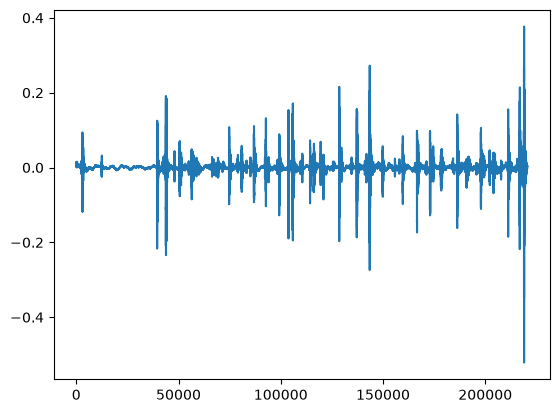

In [9]:
plt.plot(audio)

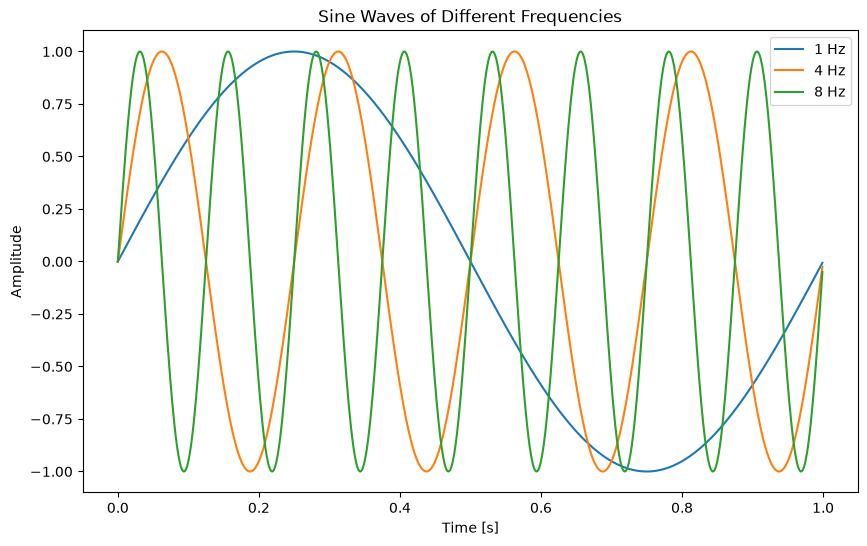

In [10]:
t = np.linspace(0, 1, 1000, endpoint=False)
frequencies = [1, 4, 8]

plt.figure(figsize=(10, 6))
for freq in frequencies:
    y = np.sin(2 * np.pi * freq * t)
    plt.plot(t, y, label=f'{freq} Hz')

plt.title('Sine Waves of Different Frequencies')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

In [11]:
audio.dtype

torch.float32

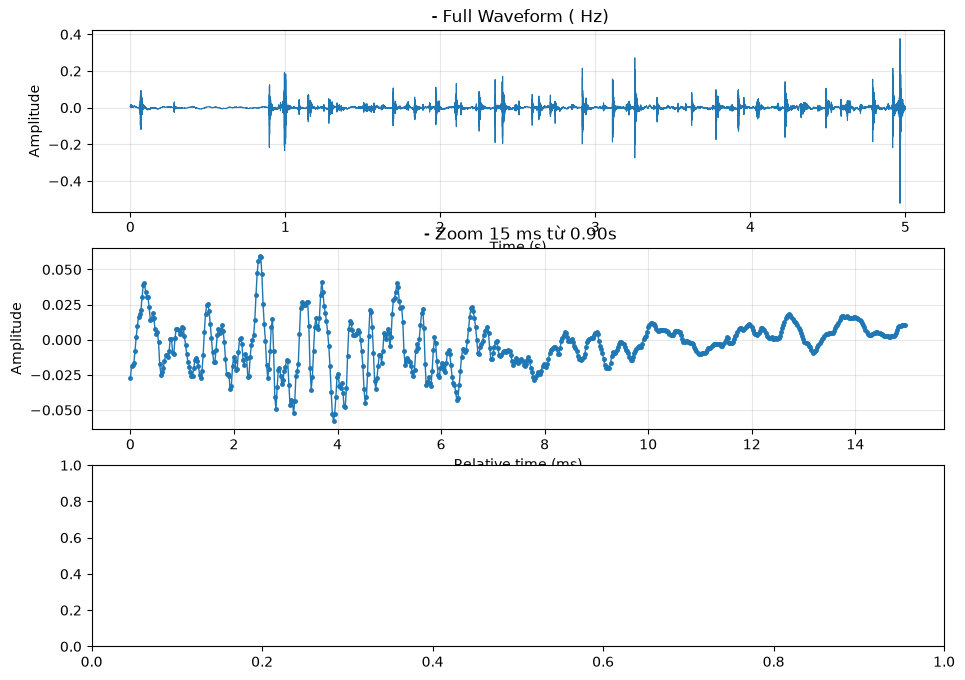

In [14]:
wave_1d = audio.squeeze(0).detach().cpu().numpy()
time_axis = torch.arange(len(wave_1d)) / sample_rate

fig, axes = plt.subplots(3, 1, figsize=(11, 8))

# Subplot 1: Toàn bộ waveform theo thời gian (giây)
axes[0].plot(time_axis.numpy(), wave_1d, linewidth=0.8)
axes[0].set_title(f" - Full Waveform ( Hz)")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

# Subplot 2: Zoom 15 ms quanh mốc ~0.9s (nơi các xung mạnh bắt đầu xuất hiện)
start_idx = int(0.9 * sample_rate)
end_idx = start_idx + int(0.015 * sample_rate)
t_ms = (torch.arange(end_idx - start_idx) / sample_rate).numpy() * 1000
axes[1].plot(t_ms, wave_1d[start_idx:end_idx], marker="o", markersize=2.5, linewidth=1)
axes[1].set_title(f" - Zoom 15 ms từ 0.90s")
axes[1].set_xlabel("Relative time (ms)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)